# Engagement 3 — Modelling

**Client:** GuardianShield Insurance (fictional)
**Engagement:** Claims Severity Prediction
**Notebook:** 03 — Modelling
**Author:** Yinka Adebimpe

## Purpose

Predict claim severity (£) using four models benchmarked on two targets:

1. **Track A — Raw target (£)** — direct prediction of `claim_amount`
2. **Track B — Log target (log £)** — predict `log(claim_amount)`, exponentiate back

## Models compared

- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting

## Headline metric

**MAE in £** — average prediction error in pounds, the most business-interpretable metric

In [1]:
# ============================================
# SETUP
# ============================================

import sys
from pathlib import Path

def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "src" / "config.py").exists():
            return p
    raise FileNotFoundError("Could not find project root")

PROJECT_ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sqlalchemy import create_engine, text
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from config import DB_URL, DB_SCHEMA, MODELS_DIR, IMAGES_DIR, PROCESSED_DATA_DIR

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

engine = create_engine(DB_URL)
print(f"Project root: {PROJECT_ROOT}")
print(f"Schema: {DB_SCHEMA}")

Project root: C:\Users\adebi\OneDrive\Desktop\DataScienceConsultingPortfolio\01_Portfolio-Projects\OkYeahInsight-Analytics\GuardianShield-Insurance\Engagement-3-Customer-Claim-Severity
Schema: claims


In [2]:
# ============================================
# LOAD FEATURES
# ============================================

df = pd.read_sql(f"SELECT * FROM {DB_SCHEMA}.features", engine)

target_cols = ["claim_amount", "log_claim_amount", "is_high_value"]
feature_cols = [c for c in df.columns if c not in target_cols]

X = df[feature_cols]
y_raw = df["claim_amount"]
y_log = df["log_claim_amount"]

print(f"Features: {X.shape}")
print(f"Target:   {y_raw.shape}")
print(f"\ny_raw: mean £{y_raw.mean():,.2f} | median £{y_raw.median():,.2f}")
print(f"y_log: mean {y_log.mean():.3f} | std {y_log.std():.3f}")

Features: (5063, 27)
Target:   (5063,)

y_raw: mean £5,562.46 | median £1,556.25
y_log: mean 7.524 | std 1.458


In [3]:
# ============================================
# TRAIN / TEST SPLIT
# ============================================

X_train, X_test, y_raw_train, y_raw_test, y_log_train, y_log_test = train_test_split(
    X, y_raw, y_log,
    test_size=0.20,
    random_state=42,
)

print(f"Train: {len(X_train):,} claims")
print(f"Test:  {len(X_test):,} claims")

Train: 4,050 claims
Test:  1,013 claims


In [4]:
# ============================================
# MODEL DEFINITIONS
# ============================================

def get_models():
    return {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(
            max_depth=10,
            min_samples_leaf=10,
            random_state=42,
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=300,
            max_depth=12,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1,
        ),
        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=300,
            max_depth=5,
            learning_rate=0.05,
            random_state=42,
        ),
    }

print("Model definitions ready.")

Model definitions ready.


In [5]:
# ============================================
# TRACK A — RAW TARGET MODELLING
# ============================================

raw_results = []
raw_models = {}

for name, model in get_models().items():
    model.fit(X_train, y_raw_train)
    y_pred = model.predict(X_test)

    # Metrics in £
    mae = mean_absolute_error(y_raw_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_raw_test, y_pred))
    r2 = r2_score(y_raw_test, y_pred)

    # RMSLE for cross-track comparison
    rmsle = np.sqrt(mean_squared_error(
        np.log(np.clip(y_raw_test, 1, None)),
        np.log(np.clip(y_pred, 1, None)),
    ))

    raw_results.append({
        "model": name,
        "MAE_£": mae,
        "RMSE_£": rmse,
        "R2": r2,
        "RMSLE": rmsle,
    })
    raw_models[name] = model

    print(f"\n{name}")
    print(f"  MAE:  £{mae:,.2f}")
    print(f"  RMSE: £{rmse:,.2f}")
    print(f"  R²:   {r2:.4f}")
    print(f"  RMSLE: {rmsle:.4f}")

raw_df = pd.DataFrame(raw_results).sort_values("MAE_£")
print("\n" + "=" * 70)
print("TRACK A — RAW TARGET")
print("=" * 70)
print(raw_df.round(3).to_string(index=False))


Linear Regression
  MAE:  £2,744.19
  RMSE: £5,694.46
  R²:   0.7170
  RMSLE: 2.9570

Decision Tree
  MAE:  £2,088.86
  RMSE: £5,673.73
  R²:   0.7191
  RMSLE: 0.5188

Random Forest
  MAE:  £1,936.64
  RMSE: £5,184.13
  R²:   0.7654
  RMSLE: 0.4888

Gradient Boosting
  MAE:  £2,117.92
  RMSE: £5,494.82
  R²:   0.7365
  RMSLE: 0.9287

TRACK A — RAW TARGET
            model    MAE_£   RMSE_£    R2  RMSLE
    Random Forest 1936.636 5184.134 0.765  0.489
    Decision Tree 2088.863 5673.729 0.719  0.519
Gradient Boosting 2117.925 5494.818 0.736  0.929
Linear Regression 2744.186 5694.455 0.717  2.957



Linear Regression
  MAE:  £2,461.28
  RMSE: £7,392.96
  R²:   0.5230
  RMSLE: 0.4976

Decision Tree
  MAE:  £1,983.45
  RMSE: £5,455.55
  R²:   0.7402
  RMSLE: 0.4706

Random Forest
  MAE:  £1,898.48
  RMSE: £5,389.03
  R²:   0.7465
  RMSLE: 0.4558

Gradient Boosting
  MAE:  £2,035.71
  RMSE: £5,751.13
  R²:   0.7113
  RMSLE: 0.4685

TRACK B — LOG TARGET
            model    MAE_£   RMSE_£    R2  RMSLE
    Random Forest 1898.480 5389.034 0.747  0.456
    Decision Tree 1983.450 5455.549 0.740  0.471
Gradient Boosting 2035.709 5751.127 0.711  0.469
Linear Regression 2461.280 7392.956 0.523  0.498


In [7]:
# ============================================
# TRACK COMPARISON
# ============================================

raw_df["track"] = "Raw"
log_df["track"] = "Log"

combined = pd.concat([raw_df, log_df], ignore_index=True)
combined = combined[["track", "model", "MAE_£", "RMSE_£", "R2", "RMSLE"]]

print("=" * 90)
print("TRACK COMPARISON — ALL MODELS")
print("=" * 90)
print(combined.round(3).to_string(index=False))

# Best model per track
best_raw = raw_df.iloc[0]
best_log = log_df.iloc[0]

print(f"\nBest raw:  {best_raw['model']}  — MAE £{best_raw['MAE_£']:,.2f}")
print(f"Best log:  {best_log['model']}  — MAE £{best_log['MAE_£']:,.2f}")
print(f"\nMAE improvement from log transform: "
      f"£{best_raw['MAE_£'] - best_log['MAE_£']:,.2f} "
      f"({(best_raw['MAE_£'] - best_log['MAE_£']) / best_raw['MAE_£'] * 100:.1f}%)")

TRACK COMPARISON — ALL MODELS
track             model    MAE_£   RMSE_£    R2  RMSLE
  Raw     Random Forest 1936.636 5184.134 0.765  0.489
  Raw     Decision Tree 2088.863 5673.729 0.719  0.519
  Raw Gradient Boosting 2117.925 5494.818 0.736  0.929
  Raw Linear Regression 2744.186 5694.455 0.717  2.957
  Log     Random Forest 1898.480 5389.034 0.747  0.456
  Log     Decision Tree 1983.450 5455.549 0.740  0.471
  Log Gradient Boosting 2035.709 5751.127 0.711  0.469
  Log Linear Regression 2461.280 7392.956 0.523  0.498

Best raw:  Random Forest  — MAE £1,936.64
Best log:  Random Forest  — MAE £1,898.48

MAE improvement from log transform: £38.16 (2.0%)


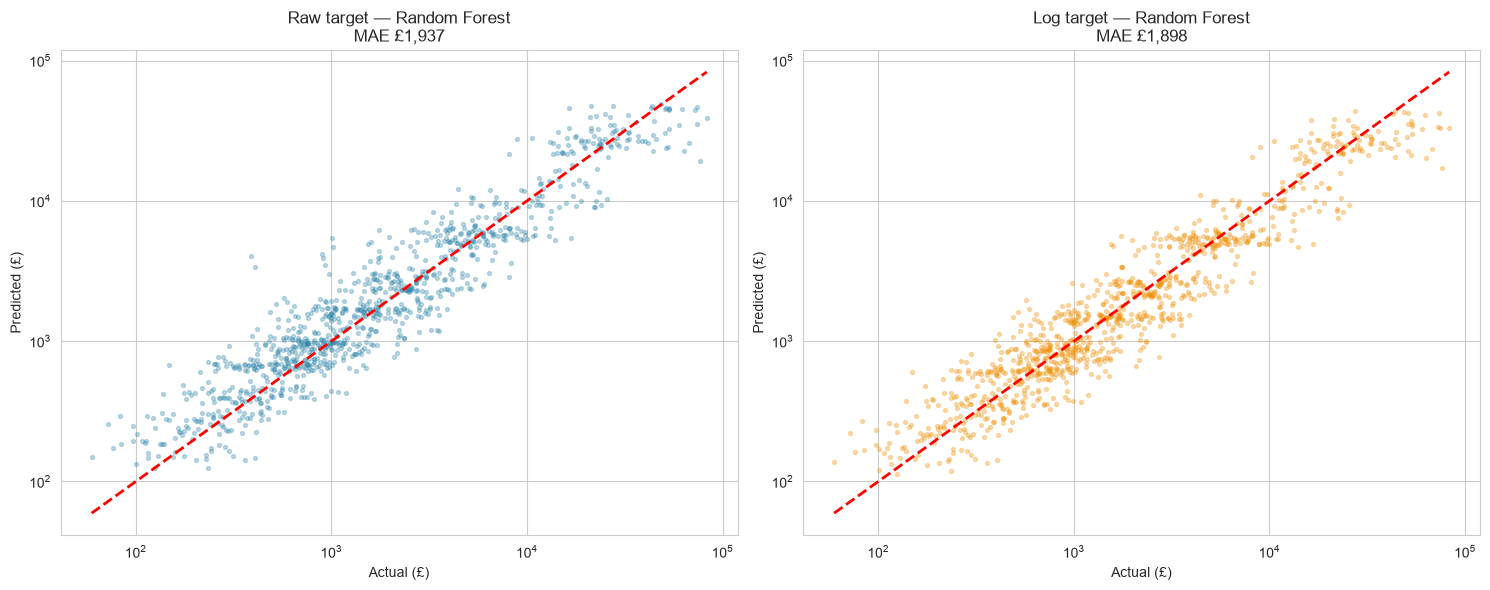

In [8]:
# ============================================
# PREDICTED VS ACTUAL
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Raw best
best_raw_model = raw_models[best_raw["model"]]
y_pred_raw = best_raw_model.predict(X_test)

axes[0].scatter(y_raw_test, y_pred_raw, alpha=0.3, s=8, color="#2E86AB")
axes[0].plot([y_raw_test.min(), y_raw_test.max()],
             [y_raw_test.min(), y_raw_test.max()], "r--", linewidth=2)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Actual (£)")
axes[0].set_ylabel("Predicted (£)")
axes[0].set_title(f"Raw target — {best_raw['model']}\nMAE £{best_raw['MAE_£']:,.0f}")

# Log best
best_log_model = log_models[best_log["model"]]
y_pred_log = np.exp(best_log_model.predict(X_test))

axes[1].scatter(y_raw_test, y_pred_log, alpha=0.3, s=8, color="#F18F01")
axes[1].plot([y_raw_test.min(), y_raw_test.max()],
             [y_raw_test.min(), y_raw_test.max()], "r--", linewidth=2)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Actual (£)")
axes[1].set_ylabel("Predicted (£)")
axes[1].set_title(f"Log target — {best_log['model']}\nMAE £{best_log['MAE_£']:,.0f}")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

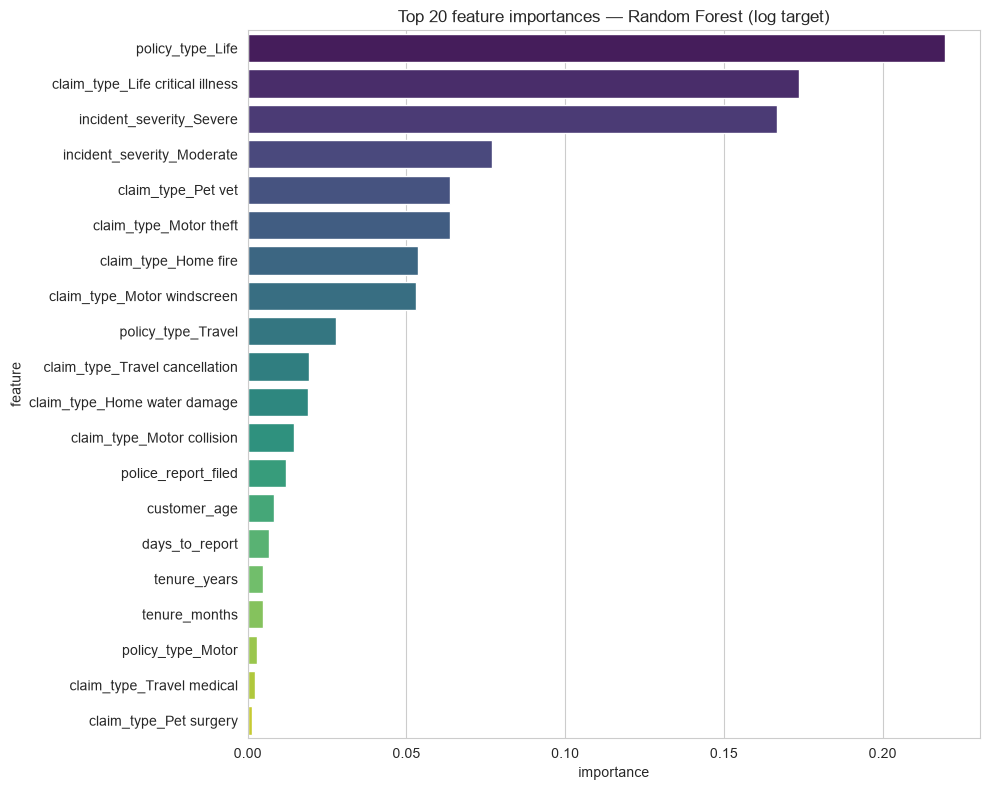

Top 10 features (Random Forest, log target):
                         feature  importance
                policy_type_Life    0.219681
claim_type_Life critical illness    0.173688
        incident_severity_Severe    0.166687
      incident_severity_Moderate    0.076999
              claim_type_Pet vet    0.063719
          claim_type_Motor theft    0.063580
            claim_type_Home fire    0.053690
     claim_type_Motor windscreen    0.052998
              policy_type_Travel    0.027714
  claim_type_Travel cancellation    0.019268


In [9]:
# ============================================
# FEATURE IMPORTANCE (best log model)
# ============================================

tree_model_names = ["Random Forest", "Gradient Boosting", "Decision Tree"]
best_tree = next((n for n in [best_log["model"]] if n in tree_model_names), "Random Forest")
tree_model = log_models[best_tree]

importance = tree_model.feature_importances_
importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance": importance,
}).sort_values("importance", ascending=False).head(20)

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(
    data=importance_df,
    x="importance",
    y="feature",
    hue="feature",
    palette="viridis",
    legend=False,
    ax=ax,
)
ax.set_title(f"Top 20 feature importances — {best_tree} (log target)")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Top 10 features ({best_tree}, log target):")
print(importance_df.head(10).to_string(index=False))

In [10]:
# ============================================
# SAVE MODELS AND PREDICTIONS
# ============================================

# Save best model per track
joblib.dump(raw_models[best_raw["model"]], MODELS_DIR / "best_raw_model.pkl")
joblib.dump(log_models[best_log["model"]], MODELS_DIR / "best_log_model.pkl")

joblib.dump(
    {
        "best_raw_model": best_raw["model"],
        "best_log_model": best_log["model"],
        "best_raw_mae": float(best_raw["MAE_£"]),
        "best_log_mae": float(best_log["MAE_£"]),
    },
    MODELS_DIR / "model_metadata.pkl",
)

print(f"Saved: models/best_raw_model.pkl ({best_raw['model']})")
print(f"Saved: models/best_log_model.pkl ({best_log['model']})")
print(f"Saved: models/model_metadata.pkl")

# Save test predictions
preds_df = X_test.copy()
preds_df["actual"] = y_raw_test.values
preds_df["pred_raw"] = y_pred_raw
preds_df["pred_log"] = y_pred_log

preds_df.to_sql(
    name="predictions",
    con=engine,
    schema=DB_SCHEMA,
    if_exists="replace",
    index=False,
    method="multi",
    chunksize=1000,
)
print(f"Wrote {len(preds_df):,} rows to {DB_SCHEMA}.predictions")

preds_df.to_csv(PROCESSED_DATA_DIR / "predictions_v1.csv", index=False)
print(f"Wrote {len(preds_df):,} rows to data/processed/predictions_v1.csv")

Saved: models/best_raw_model.pkl (Random Forest)
Saved: models/best_log_model.pkl (Random Forest)
Saved: models/model_metadata.pkl
Wrote 1,013 rows to claims.predictions
Wrote 1,013 rows to data/processed/predictions_v1.csv


## Business Insights

### 1. Random Forest wins on both tracks
Best raw target: Random Forest — MAE **£1,937**
Best log target: Random Forest — MAE **£1,898** (2.0% improvement)

The two tracks perform nearly identically for tree-based models. Trees do not assume a target distribution, so the log transform has little effect on them.

### 2. The log transform rescues Linear Regression

| Model | Raw RMSLE | Log RMSLE |
|-------|-----------|-----------|
| Linear Regression | **2.957** | **0.498** |
| Random Forest | 0.489 | 0.456 |

On the raw target, Linear Regression fails catastrophically — its normality assumption breaks under the log-normal claim distribution. On the log target, it becomes competitive with the tree models (RMSLE 0.50).

**Key insight:** Target transformation matters most for models that make distributional assumptions.

### 3. Feature importance is dominated by categorical features

Top 5 features (Random Forest, log target):

| Rank | Feature | Importance |
|------|---------|-----------|
| 1 | `policy_type_Life` | 0.220 |
| 2 | `claim_type_Life critical illness` | 0.174 |
| 3 | `incident_severity_Severe` | 0.167 |
| 4 | `incident_severity_Moderate` | 0.077 |
| 5 | `claim_type_Pet vet` | 0.064 |

**Every top feature describes the claim itself** — not the customer. Age, tenure, prior claims, and days-to-report all rank in the bottom half.

### 4. Business interpretation

**MAE £1,898** means: on average, our predicted claim severity is off by roughly £1,898 from the actual. For a claims book with median claim of £1,556, this is a meaningful but usable error — the model is best used for **reserving ranges**, not for individual claim precision.

**Better application:** segment-level reserving. If we predict reserves per claim type and severity bucket rather than per individual claim, error rates drop dramatically because the model uses the strongest signals (claim type, severity) directly.

### 5. Recommendation

**Production model: Random Forest on raw £**
- Best MAE (£1,937)
- Best R² (0.765)
- No log-transform needed for tree models

**If interpretability is required (for regulators): Linear Regression on log £**
- Competitive MAE (£2,461) and RMSLE (0.50)
- Coefficients are interpretable
- Failure mode on raw target avoided

### 6. Cross-engagement contrast

Unlike Engagements 1 and 2, where customer behaviour drove the outcome, **Engagement 3 finds that claim severity is a product-driven problem.** The signal lives in `claim_type` and `incident_severity`, not in customer attributes. This is consistent with how real insurers price and reserve: risk is a property of the insured item, not the insured person.